# Step 1 - Loading, BIDS conversion and quality control

This notebook walks through step 1 on the real data. It **reads** what the scripts produced; it does not recompute the whole pipeline:

1. `scripts/01_convert_to_bids.py` converted the 22 NIX files to BIDS (`data/bids/`);
2. `scripts/02_quality_control.py` computed the QC tables (`results/qc_*.csv`) and figures.

Prerequisite: run both scripts first (`.\run.ps1 run`).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.signal import butter, sosfiltfilt

from epidetect import io, plotting, qc
from epidetect.config import load_config

warnings.filterwarnings("ignore", category=RuntimeWarning)  # missing electrode coordinates
plotting.apply_style()
%matplotlib inline
cfg = load_config()
bids_root, results, figures = (cfg["paths"][k] for k in ("bids_root", "results_dir", "figures_dir"))
pd.set_option("display.width", 160)

## 1. The BIDS dataset

`participants.tsv` holds the clinical metadata read from the NIX files. There is no channel-level resection information: `resection_area` is free text.

In [2]:
participants = pd.read_csv(bids_root / "participants.tsv", sep="\t")
participants

,participant_id,age,sex,etiology,resection_area,ilae,seizure_free,follow_up_months,electrode
0,sub-01,15,F,DNET (WHO I),L medial parietal,1,True,33,4x8 grid
1,sub-02,7,F,FCD 2b,L dorsal medial prefrontal,1,True,24,4x8 grid
2,sub-03,17,M,Sturge Weber syndrome,L lateral occipital,1,True,30,4x8 grid
3,sub-04,22,M,ganglioglioma (WHO I),R posterior fusiform gyrus (occipital),1,True,18,4x8 grid
4,sub-05,20,F,FCD 2a,R posterior temporal,1,True,13,4x8 grid
5,sub-06,3,F,Sturge Weber syndrome,R lateral posterior temporal & lateral occipital,3,False,20,4x8 grid
6,sub-07,34,M,astrocytoma (WHO II),R posterior middle frontal gyrus,1,True,29,2x14 grid
7,sub-08,23,F,FCD 2a,"R posterior cingulate gyrus, posterior hippoca...",1,True,12,4x8 grid
8,sub-09,1,M,FCD 2a,R dorsal lateral prefrontal,1,True,43,1x4 strip
9,sub-10,15,F,Sturge Weber syndrome,L lateral parieto-occipital & medial temporal,3,False,30,1x6 strip


In [3]:
ieeg_dir = bids_root / "sub-01" / "ses-preresection" / "ieeg"
print(*sorted(p.name for p in ieeg_dir.iterdir()), sep="\n")

sub-01_ses-preresection_coordsystem.json
sub-01_ses-preresection_electrodes.json
sub-01_ses-preresection_electrodes.tsv
sub-01_ses-preresection_task-intraop_channels.tsv
sub-01_ses-preresection_task-intraop_events.json
sub-01_ses-preresection_task-intraop_events.tsv
sub-01_ses-preresection_task-intraop_ieeg.eeg
sub-01_ses-preresection_task-intraop_ieeg.json
sub-01_ses-preresection_task-intraop_ieeg.vhdr
sub-01_ses-preresection_task-intraop_ieeg.vmrk


## 2. One recording as an MNE `Raw` object

`read_bids_recording` restores channel-specific FR annotations from the extra `channel` column of `events.tsv`. MNE stores data in **volts**; we convert to microvolts for display.

In [4]:
raw = io.read_bids_recording(bids_root, "01", "pre")
print(raw)
print("sampling rate:", raw.info["sfreq"], "Hz | line frequency:", raw.info["line_freq"], "Hz")
markings = io.annotations_to_markings(raw)
print(len(markings), "FR markings; busiest channels:")
print(markings["channel"].value_counts().head())

<RawBrainVision | sub-01_ses-preresection_task-intraop_ieeg.eeg, 28 x 1000000 (500.0 s), ~38 KiB, data not loaded>
sampling rate: 2000.0 Hz | line frequency: 50.0 Hz
175 FR markings; busiest channels:
channel
18-19    50
17-18    30
25-26    20
01-02    14
02-03    13
Name: count, dtype: int64


## 3. What a marked fast ripple looks like

Left: the raw signal around one marked FR (the one whose duration is closest to 15 ms). Right: the same segment band-passed in 250-500 Hz. Filter design (order, zero phase with `filtfilt`, edge effects) is explained in step 3; here it is only a preview.

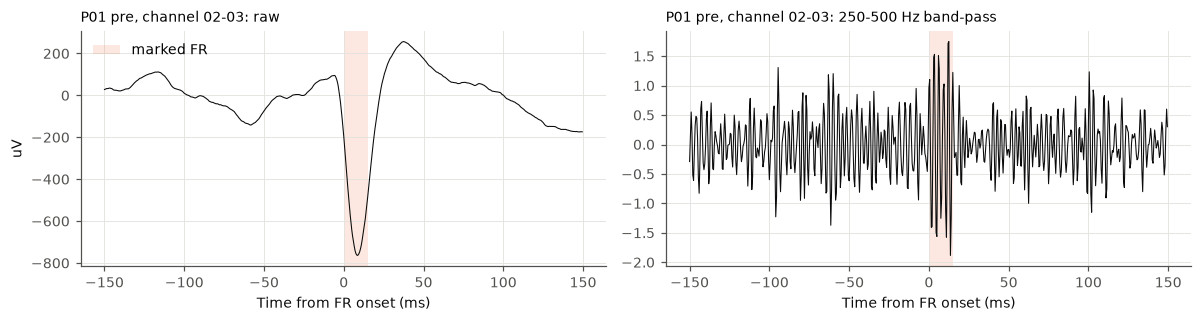

In [5]:
fs = raw.info["sfreq"]
fr = markings.iloc[markings["duration_s"].sub(0.015).abs().argmin()]  # a typical ~15 ms FR
ch = raw.ch_names.index(fr.channel)
start, stop = int((fr.onset_s - 0.15) * fs), int((fr.onset_s + 0.15) * fs)
whole_uv = raw.get_data(picks=[ch])[0] / io.MICROVOLT
sos = butter(4, [250, 500], btype="bandpass", fs=fs, output="sos")
filtered_uv = sosfiltfilt(sos, whole_uv)[start:stop]  # filter the whole channel: no edge effects here
segment_uv = whole_uv[start:stop]
t_ms = (np.arange(start, stop) / fs - fr.onset_s) * 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True)
for ax, y, title in [(axes[0], segment_uv, "raw"), (axes[1], filtered_uv, "250-500 Hz band-pass")]:
    ax.axvspan(0, fr.duration_s * 1000, color=plotting.ACCENT, alpha=0.15, lw=0, label="marked FR")
    ax.plot(t_ms, y, color=plotting.INK, lw=0.7)
    ax.set_title(f"P01 pre, channel {fr.channel}: {title}", loc="left")
    ax.set_xlabel("Time from FR onset (ms)")
axes[0].set_ylabel("uV")
axes[0].legend(loc="upper left")
fig.tight_layout()

What this example shows:

* The marked FR coincides with a large **epileptic spike** (several hundred uV, tens of ms). In the raw trace, nothing at 250-500 Hz is visible: the slow, large components dominate, as expected from the 1/f spectrum.
* After band-pass filtering, a burst of about 1-2 uV appears, only a few times larger than the filtered background (amplifier noise floor).
* **Open question for step 3:** is this burst a genuine oscillation riding on the spike, or the band-pass filter's impulse response to a sharp transient (the Gibbs-like ringing that makes a filtered spike look like an HFO)? The reference markings were visually validated, but this ambiguity is exactly why detectors need a time-frequency check.

## 4. Why the QC uses a *median* Welch PSD

Patient 06 has 1,413 FRs. On its channel with the most FRs, compare the 250-500 Hz power of the mean-averaged and the median-averaged Welch PSD. The mean is pulled up by the windows that contain FRs; the median describes the background. A QC based on the mean would risk flagging the most epileptic channels as "noisy".

In [6]:
raw06 = io.read_bids_recording(bids_root, "06", "pre")
m06 = io.annotations_to_markings(raw06)
busiest = m06["channel"].value_counts().idxmax()
x = raw06.get_data(picks=[busiest]) / io.MICROVOLT
f, p_mean = qc.welch_psd(x, raw06.info["sfreq"], average="mean")
_, p_median = qc.welch_psd(x, raw06.info["sfreq"], average="median")
band = tuple(cfg["qc"]["fast_ripple_band_hz"])
ratio = qc.band_power(f, p_mean, band)[0] / qc.band_power(f, p_median, band)[0]
print(f"P06 channel {busiest}: {(m06.channel == busiest).sum()} FRs, "
      f"mean/median 250-500 Hz power ratio = {ratio:.2f}")

P06 channel 07-08: 124 FRs, mean/median 250-500 Hz power ratio = 1.88


For pure Gaussian noise this ratio is about 1, because SciPy's median includes a bias correction that is exact for Gaussian noise. A ratio clearly above 1 measures how much the transients (FRs and artefacts) inflate the mean.

## 5. QC results

### 5.1 Duplicated recordings
The integrity check hashes every channel. Patients 12, 15 and 17 share byte-identical pre-resection recordings and are excluded (`configs/default.toml`, `[data] excluded_recordings`).

In [7]:
duplicates = pd.read_csv(results / "qc_duplicates.csv", dtype=str)
duplicates.groupby("group").agg(lambda s: ", ".join(sorted(set(s))))

,patient,session,channel
group,,,
0,"12, 15, 17",pre,1-2
1,"12, 15, 17",pre,2-3
2,"12, 15, 17",pre,3-4
3,"12, 15, 17",pre,4-5


### 5.2 One row per recording

In [8]:
recordings = pd.read_csv(results / "qc_recordings.csv", dtype={"patient": str})
recordings

,patient,session,n_channels,n_flagged,median_std_uv,median_aperiodic_beta,n_fr,excluded,worst_harmonic_median_db
0,01,post,15,0,138.826,3.191,0,False,0.135
1,01,pre,28,0,128.870,2.682,175,False,0.745
2,02,post,22,2,307.678,2.928,4,False,4.333
3,02,pre,19,4,239.408,2.129,70,False,2.433
4,03,post,10,0,143.346,2.967,1,False,4.076
5,03,pre,21,0,89.044,2.713,6,False,0.426
6,04,post,17,0,89.575,2.770,0,False,1.081
7,04,pre,25,0,130.380,2.234,63,False,0.825
8,05,post,19,2,81.022,3.112,0,False,1.136
9,05,pre,23,3,125.302,2.410,231,False,0.792


### 5.3 Flagged channels

In [9]:
channels = pd.read_csv(results / "qc_channels.csv", dtype={"patient": str})
analysed = channels[~channels.excluded_recording]
print(f"{analysed.bad.sum()} flagged / {len(analysed)} analysed channels; "
      f"{analysed.loc[analysed.bad, 'n_fr'].sum()} reference FRs on flagged channels")
analysed.loc[analysed.bad, ["patient", "session", "channel", "n_fr", "reasons"]]

18 flagged / 429 analysed channels; 18 reference FRs on flagged channels


,patient,session,channel,n_fr,reasons
48,02,pre,09-10,0,250-500 Hz background outlier (z=+5.8)
49,02,pre,10-11,0,250-500 Hz background outlier (z=+5.7)
55,02,pre,17-18,0,250-500 Hz background outlier (z=+5.6)
61,02,pre,26-27,0,250-500 Hz background outlier (z=+5.9)
65,02,post,06-07,0,250-500 Hz background outlier (z=+6.5)
70,02,post,14-15,0,250-500 Hz background outlier (z=+5.5)
177,05,pre,29-30,0,250-500 Hz background outlier (z=+15.7)
178,05,pre,30-31,0,250-500 Hz background outlier (z=+11.6)
179,05,pre,31-32,0,250-500 Hz background outlier (z=+14.1)
194,05,post,23-24,0,250-500 Hz background outlier (z=+31.9)


The robust z-score of the 250-500 Hz background is unrelated to the number of FRs on a channel. This confirms that the median PSD does not confuse "epileptic" with "noisy". Only recordings with at least 8 channels are included, where the z-score is defined:

In [10]:
rel = analysed[analysed.z_fr.notna()]
print("Spearman correlation z_fr vs FR count:", round(rel["z_fr"].corr(rel["n_fr"], method="spearman"), 2))

Spearman correlation z_fr vs FR count: 0.06


### 5.4 Aperiodic (1/f) exponent
Fitted on 2-40 Hz in log-log space, mains harmonics excluded. These values will set the range of the simulator's background in step 2.

In [11]:
analysed["aperiodic_beta"].describe().round(2)

count    429.00
mean       2.53
std        0.47
min        0.73
25%        2.22
50%        2.55
75%        2.88
max        3.48
Name: aperiodic_beta, dtype: float64

### 5.5 Figures

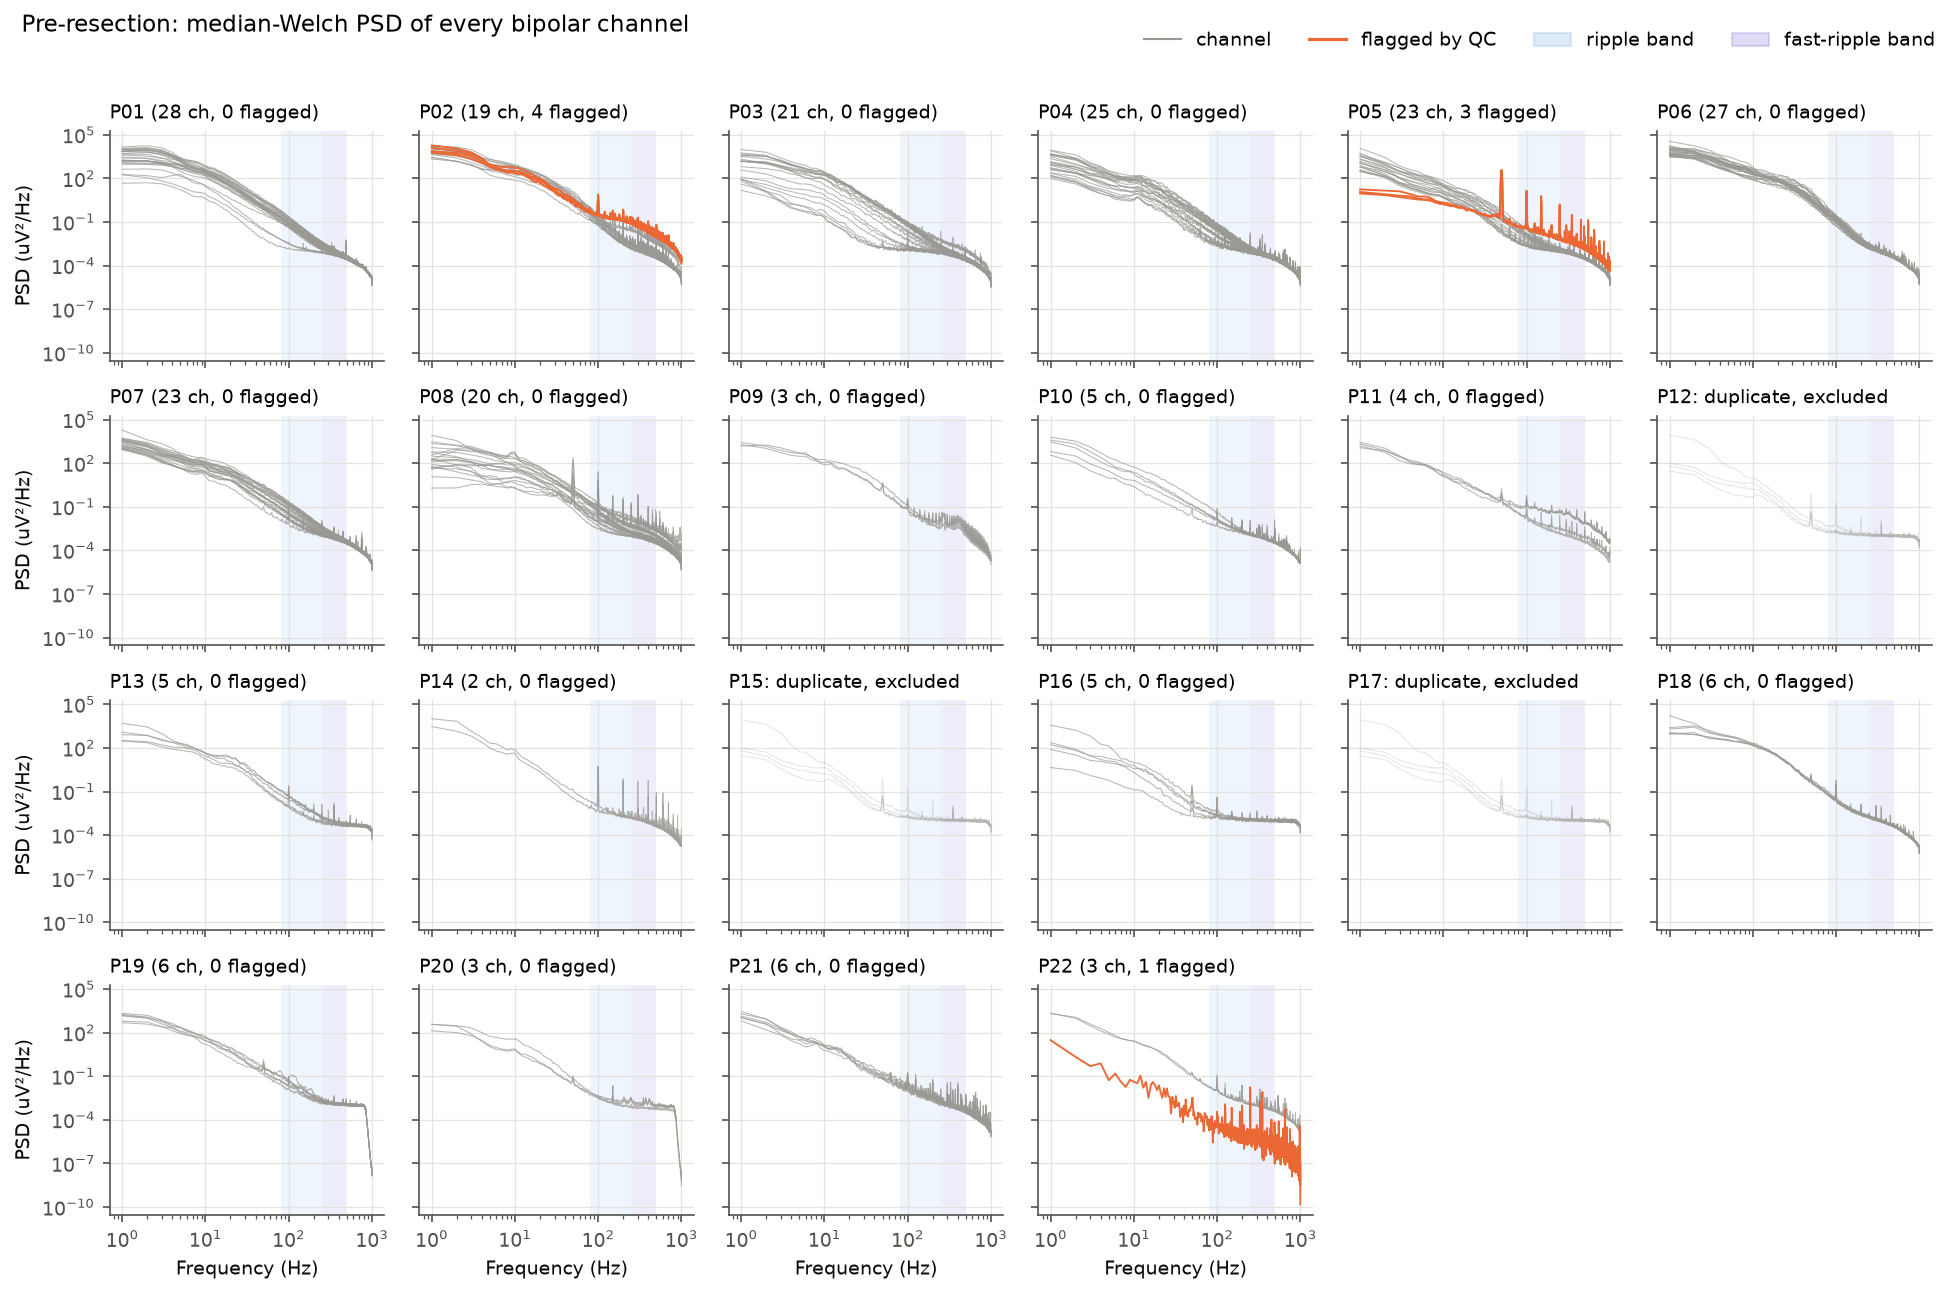

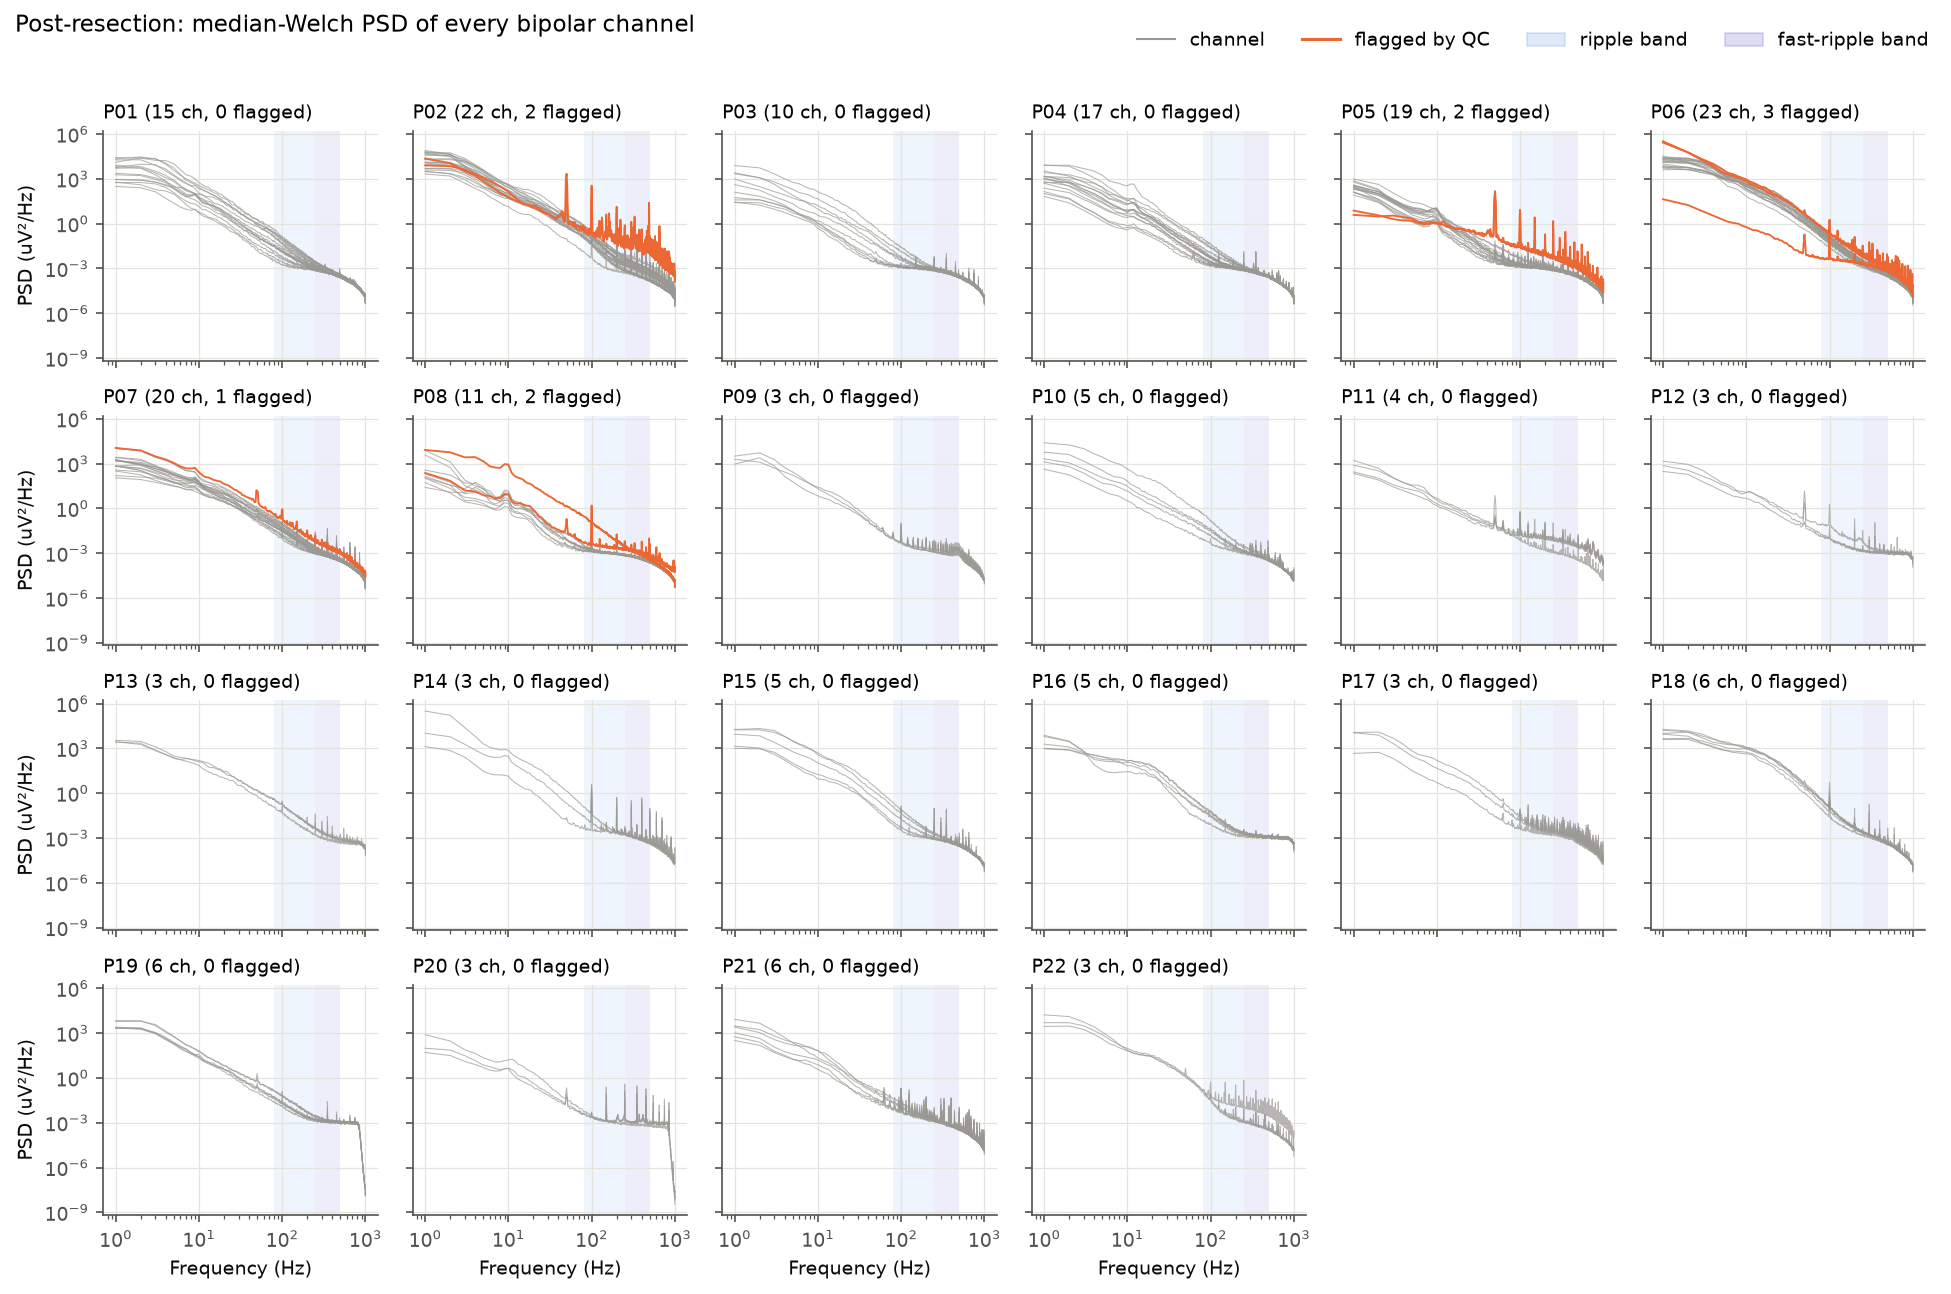

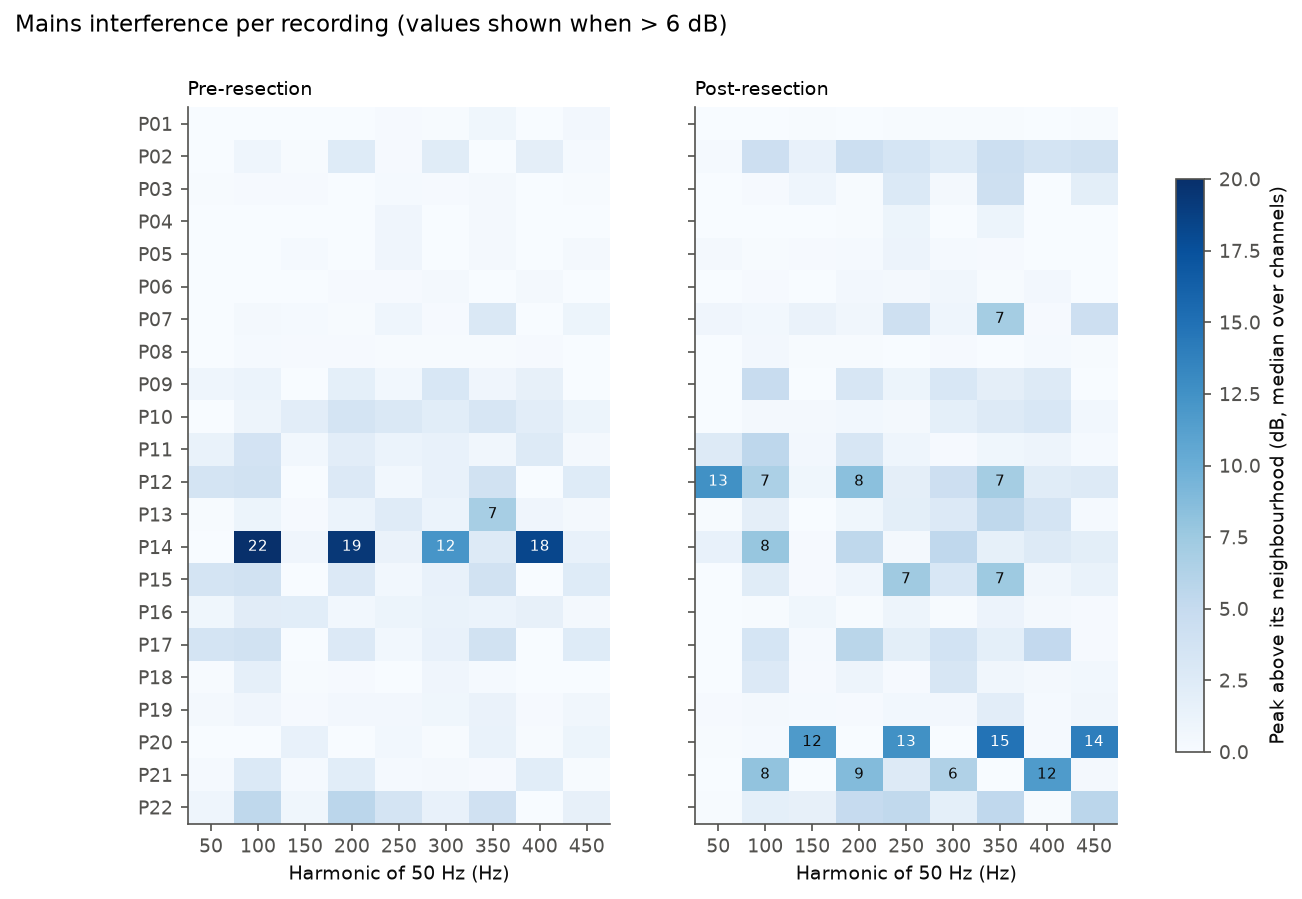

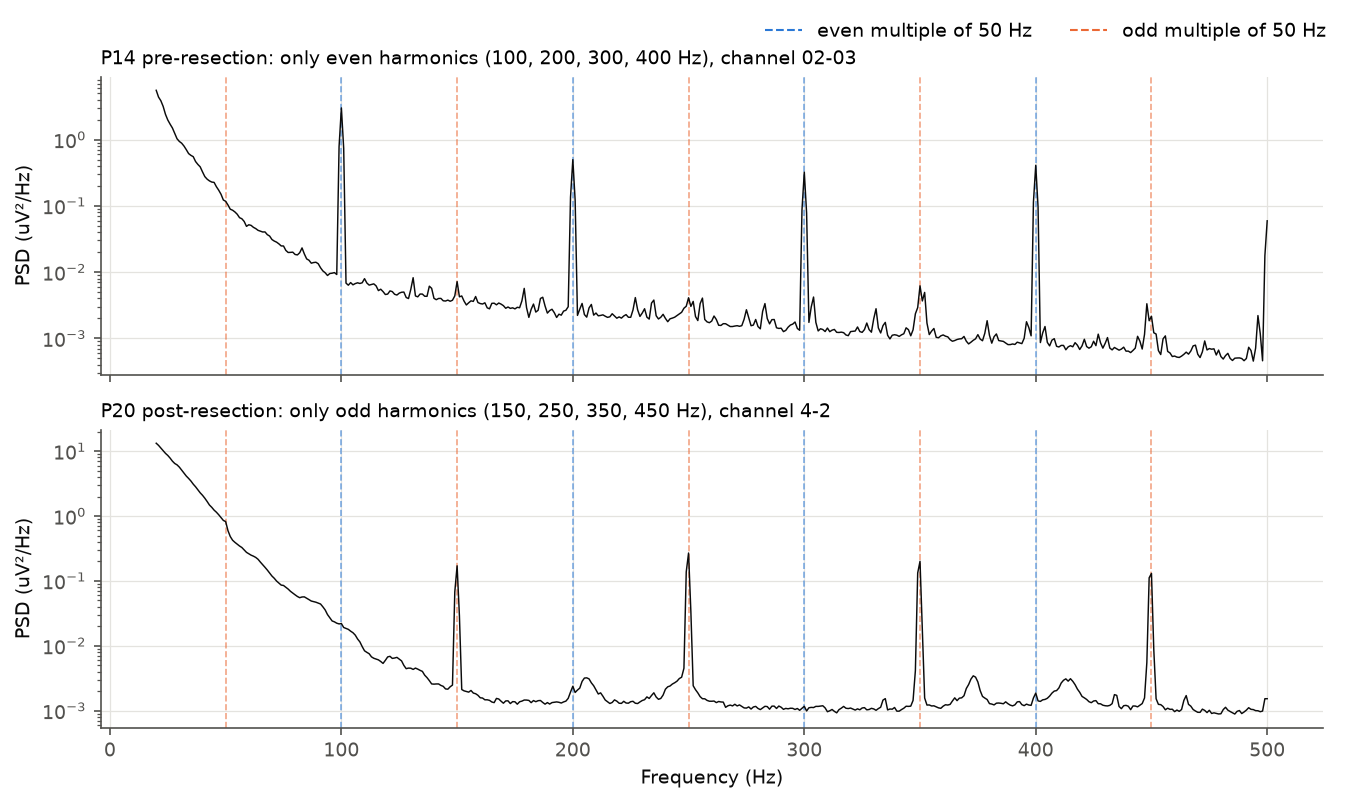

In [12]:
for name in ["qc_psd_pre", "qc_psd_post", "qc_line_noise", "qc_harmonics_examples"]:
    display(Image(filename=str(figures / f"{name}.png")))

## 6. Take-aways

* Signals are clean enough for HFO work: 2000 Hz sampling, 1-800 Hz hardware band, bipolar montage.
* In many channels the spectrum flattens above ~150-250 Hz: the fast-ripple band sits on the **amplifier noise floor**. The simulator must include a white-noise floor, not only 1/f.
* Mains harmonics fall inside the ripple and FR bands for a few recordings (e.g. P14, P20, P21): whether to notch-filter is decided in step 3.
* Three recordings are duplicates and are excluded. QC-flagged channels are kept for the main analysis, and a sensitivity analysis excludes them.